# Project Deliverable 1: Data Collection, Cleaning, and Exploration
**Name:** Rohail Shaikh  
**Course:** Advanced Big Data and Data Mining (MSCS-634-M50)  
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling

## 1. Dataset selection and purpose
This project examines how time, weather, and working days relate to hourly bike rentals.
The practical goal is to support decisions about when more bicycles and staff may be needed.

The **UCI Bike Sharing dataset** contains Capital Bikeshare rental counts in Washington, D.C.,
from January 1, 2011, through December 31, 2012 (Fanaee-T, 2013). The supplied `hour.csv`
has **17,379 records and 17 original columns**, exceeding the requirement of 500 records and
8–10 attributes. Each row represents one recorded hour across the system, not an individual rider.
It includes numeric measurements, calendar categories, and a numeric outcome, making it suitable
for the full project.

| Later task | How this dataset can support it |
|---|---|
| Regression | Predict total hourly rentals from calendar and weather features. |
| Classification | Predict high-demand hours using a threshold defined from training data. Exclude the rental count and its components from predictors. |
| Clustering | Group hours by standardized weather and encoded time features, then compare demand across groups. |
| Association mining | Treat each hour as a set of conditions, such as `weather=clear`, `working_day=yes`, and a demand category. These are condition patterns, not shopping baskets. |

**Source:** https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset  
**Dataset DOI:** https://doi.org/10.24432/C5W894  
**License:** [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
The original CSV is included so the notebook can run without downloading data.
The current UCI web page lists 17,389 instances, but the downloaded CSV and its bundled
description contain 17,379 hourly records. This notebook uses the actual file count.

### Attribute descriptions
The cleaned names are easier to read. Numeric category codes are labels, not continuous measurements.

| Original column | Cleaned column | Meaning and valid values |
|---|---|---|
| `instant` | Removed | Source row identifier; does not describe rental demand. |
| `dteday` | `date` | Calendar date. |
| `season` | `season` | 1 = winter, 2 = spring, 3 = summer, 4 = fall. |
| `yr` | `year` | Original 0 = 2011 and 1 = 2012; saved as the actual year. |
| `mnth` | `month` | Month, 1–12. |
| `hr` | `hour` | Hour, 0–23. |
| `holiday` | `holiday` | 1 = holiday, 0 = otherwise. |
| `weekday` | `weekday` | 0 = Sunday through 6 = Saturday. |
| `workingday` | `working_day` | 1 = neither a weekend nor a holiday; otherwise 0. |
| `weathersit` | `weather` | 1 = clear/partly cloudy, 2 = mist/cloudy, 3 = light rain/snow, 4 = heavy precipitation. |
| `temp` | `temperature_norm` | Normalized temperature, 0–1. |
| `atemp` | `feels_like_norm` | Normalized apparent temperature, 0–1. |
| `hum` | `humidity_norm` | Relative humidity divided by 100, 0–1. |
| `windspeed` | `windspeed_norm` | Wind speed divided by 67, 0–1. |
| `casual` | `casual_rentals` | Number of rentals by casual users; nonnegative integer. |
| `registered` | `registered_rentals` | Number of rentals by registered users; nonnegative integer. |
| `cnt` | `total_rentals` | Total hourly rentals; equals casual plus registered rentals. |
| Derived | `timestamp` | Date plus hour, used to order observations and inspect time gaps. |

The archived `Readme.txt` and the current UCI page disagree on season names and temperature
conversion formulas. Season labels above follow the current UCI page. Temperatures stay in their
original normalized units, avoiding conflicting physical-unit conversions. The cleaned file has
17 columns: the identifier is removed and the timestamp is added.

## 2. Load and inspect the data
Run this notebook from the extracted project folder. All file paths are relative to that folder.
The libraries and cleaning approach follow the preprocessing and visualization topics in Wu (2024).

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Keep tables and figures readable in Jupyter and on GitHub.
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')
ROOT = Path.cwd()
DATA_PATH = ROOT / 'hour.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError('Open this notebook from the folder containing hour.csv.')

# Recognize common missing-value markers without changing the original file.
raw = pd.read_csv(DATA_PATH, na_values=['?', 'NA', 'N/A', 'null', ''])
raw.columns = raw.columns.str.strip()
print(f'Original dataset: {raw.shape[0]:,} rows and {raw.shape[1]} columns')
print('Raw CSV SHA-256:', hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
display(raw.head())
raw.info()

Original dataset: 17,379 rows and 17 columns
Raw CSV SHA-256: e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.240,0.288,0.810,0.000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.220,0.273,0.800,0.000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.220,0.273,0.800,0.000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.240,0.288,0.750,0.000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.240,0.288,0.750,0.000,0,1,1


<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB


In [2]:
# Review numeric ranges and category frequencies before making changes.
display(raw.describe().T)
category_columns = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
                    'workingday', 'weathersit']
display(pd.DataFrame({
    'unique_values': raw[category_columns].nunique(),
    'observed_codes': [sorted(raw[col].dropna().unique().tolist())
                       for col in category_columns]
}))

,count,mean,std,min,25%,50%,75%,max
instant,"17,379.000","8,690.000","5,017.029",1.000,"4,345.500","8,690.000","13,034.500","17,379.000"
season,"17,379.000",2.502,1.107,1.000,2.000,3.000,3.000,4.000
yr,"17,379.000",0.503,0.500,0.000,0.000,1.000,1.000,1.000
mnth,"17,379.000",6.538,3.439,1.000,4.000,7.000,10.000,12.000
hr,"17,379.000",11.547,6.914,0.000,6.000,12.000,18.000,23.000
holiday,"17,379.000",0.029,0.167,0.000,0.000,0.000,0.000,1.000
weekday,"17,379.000",3.004,2.006,0.000,1.000,3.000,5.000,6.000
workingday,"17,379.000",0.683,0.465,0.000,0.000,1.000,1.000,1.000
weathersit,"17,379.000",1.425,0.639,1.000,1.000,1.000,2.000,4.000
temp,"17,379.000",0.497,0.193,0.020,0.340,0.500,0.660,1.000


,unique_values,observed_codes
season,4,"[1, 2, 3, 4]"
yr,2,"[0, 1]"
mnth,12,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]"
hr,24,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
holiday,2,"[0, 1]"
weekday,7,"[0, 1, 2, 3, 4, 5, 6]"
workingday,2,"[0, 1]"
weathersit,4,"[1, 2, 3, 4]"


## 3. Data cleaning and quality checks
The cleaning process checks missing values, duplicates, types, category codes, calendar
consistency, measurement ranges, and rental totals before removing the row identifier.

- **Missing cells:** The source contains none. No imputation is needed. The code checks common
  missing markers and stops for review if unexpected missing values appear; it never invents target values.
- **Duplicates:** Remove exact duplicate rows if found, then check date-hour keys separately.
  Conflicting records for the same hour require review rather than arbitrary deletion.
- **Inconsistencies:** Parse dates, convert numbers explicitly, validate category codes against the
  source, and check year, month, weekday, working-day status, and count totals.
- **Noise and outliers:** Use the IQR rule to flag unusual values, then examine their context.
  A high rental count can be a real busy hour, so an IQR flag alone does not justify deletion.
- **Formatting:** Rename abbreviated columns, convert year codes, sort by timestamp, and represent
  category codes as categorical data for analysis. CSV readers must restore these types later.

In [3]:
# Show missingness for every column, including columns with zero missing cells.
missing_report = pd.DataFrame({
    'missing_count': raw.isna().sum(),
    'missing_percent': raw.isna().mean() * 100
})
display(missing_report)
exact_duplicates = int(raw.duplicated().sum())
print('Exact duplicate rows:', exact_duplicates)

clean = raw.drop_duplicates().copy()
clean['dteday'] = pd.to_datetime(clean['dteday'], format='%Y-%m-%d', errors='coerce')
numeric_columns = [col for col in clean.columns if col != 'dteday']
clean[numeric_columns] = clean[numeric_columns].apply(pd.to_numeric, errors='coerce')
if clean.isna().any().any():
    raise ValueError('Missing or unparseable values found. Review them before continuing.')

# A calendar hour is the observational key, not just the source row identifier.
duplicate_hours = int(clean.duplicated(['dteday', 'hr']).sum())
if duplicate_hours:
    raise ValueError('Repeated date-hour keys need a manual consistency review.')

valid_codes = {
    'season': range(1, 5), 'yr': [0, 1], 'mnth': range(1, 13),
    'hr': range(24), 'holiday': [0, 1], 'weekday': range(7),
    'workingday': [0, 1], 'weathersit': range(1, 5)
}
invalid_codes = sum(int((~clean[col].isin(values)).sum())
                    for col, values in valid_codes.items())
measurements = ['temp', 'atemp', 'hum', 'windspeed']
invalid_measurements = sum(int((~clean[col].between(0, 1)).sum())
                           for col in measurements)
counts = clean[['casual', 'registered', 'cnt']]
invalid_counts = int(((counts < 0) | (counts % 1 != 0)).any(axis=1).sum())
total_mismatches = int((clean['cnt'] != clean['casual'] + clean['registered']).sum())

# Pandas uses Monday=0; the source uses Sunday=0.
calendar_mismatches = int((
    (clean['yr'] + 2011 != clean['dteday'].dt.year)
    | (clean['mnth'] != clean['dteday'].dt.month)
    | (clean['weekday'] != (clean['dteday'].dt.dayofweek + 1) % 7)
).sum())
expected_working_day = (~clean['weekday'].isin([0, 6]) & clean['holiday'].eq(0)).astype(int)
working_day_mismatches = int((clean['workingday'] != expected_working_day).sum())

checks = pd.Series({
    'Missing cells after parsing': int(clean.isna().sum().sum()),
    'Exact duplicates removed': exact_duplicates,
    'Repeated date-hour keys': duplicate_hours,
    'Invalid category codes': invalid_codes,
    'Out-of-range normalized measurements': invalid_measurements,
    'Invalid rental-count rows': invalid_counts,
    'Rental total mismatches': total_mismatches,
    'Calendar mismatches': calendar_mismatches,
    'Working-day mismatches': working_day_mismatches
}, name='Count')
display(checks.to_frame())
assert checks.drop('Exact duplicates removed').eq(0).all(), 'Review failed quality checks.'

,missing_count,missing_percent
instant,0,0.000
dteday,0,0.000
season,0,0.000
yr,0,0.000
mnth,0,0.000
hr,0,0.000
holiday,0,0.000
weekday,0,0.000
workingday,0,0.000
weathersit,0,0.000


Exact duplicate rows: 0


,Count
Missing cells after parsing,0
Exact duplicates removed,0
Repeated date-hour keys,0
Invalid category codes,0
Out-of-range normalized measurements,0
Invalid rental-count rows,0
Rental total mismatches,0
Calendar mismatches,0
Working-day mismatches,0


In [4]:
# Improve column names without changing the observed weather or rental values.
clean = clean.rename(columns={
    'dteday': 'date', 'yr': 'year', 'mnth': 'month', 'hr': 'hour',
    'workingday': 'working_day', 'weathersit': 'weather',
    'temp': 'temperature_norm', 'atemp': 'feels_like_norm',
    'hum': 'humidity_norm', 'windspeed': 'windspeed_norm',
    'casual': 'casual_rentals', 'registered': 'registered_rentals',
    'cnt': 'total_rentals'
})
clean['year'] = clean['year'].astype(int) + 2011
clean['timestamp'] = clean['date'] + pd.to_timedelta(clean['hour'], unit='h')
clean = clean.drop(columns='instant').sort_values('timestamp').reset_index(drop=True)

categorical_columns = ['season', 'year', 'month', 'hour', 'holiday',
                       'weekday', 'working_day', 'weather']
for col in categorical_columns:
    clean[col] = clean[col].astype('category')

# An absent hourly record is different from a blank cell or a recorded zero.
expected_hours = pd.date_range(clean['timestamp'].min(), clean['timestamp'].max(), freq='h')
missing_hours = expected_hours.difference(pd.DatetimeIndex(clean['timestamp']))
print(f'Cleaned dataset: {len(clean):,} rows and {clean.shape[1]} columns')
print(f'Coverage: {clean.date.min().date()} to {clean.date.max().date()}')
print(f'Unrecorded hours in that interval: {len(missing_hours)}')
print('First five unrecorded timestamps:', missing_hours[:5].tolist())
display(clean.head())

Cleaned dataset: 17,379 rows and 17 columns
Coverage: 2011-01-01 to 2012-12-31
Unrecorded hours in that interval: 165
First five unrecorded timestamps: [Timestamp('2011-01-02 05:00:00'), Timestamp('2011-01-03 02:00:00'), Timestamp('2011-01-03 03:00:00'), Timestamp('2011-01-04 03:00:00'), Timestamp('2011-01-05 03:00:00')]


,date,season,year,month,hour,holiday,weekday,working_day,weather,temperature_norm,feels_like_norm,humidity_norm,windspeed_norm,casual_rentals,registered_rentals,total_rentals,timestamp
0,2011-01-01,1,2011,1,0,0,6,0,1,0.240,0.288,0.810,0.000,3,13,16,2011-01-01 00:00:00
1,2011-01-01,1,2011,1,1,0,6,0,1,0.220,0.273,0.800,0.000,8,32,40,2011-01-01 01:00:00
2,2011-01-01,1,2011,1,2,0,6,0,1,0.220,0.273,0.800,0.000,5,27,32,2011-01-01 02:00:00
3,2011-01-01,1,2011,1,3,0,6,0,1,0.240,0.288,0.750,0.000,3,10,13,2011-01-01 03:00:00
4,2011-01-01,1,2011,1,4,0,6,0,1,0.240,0.288,0.750,0.000,0,1,1,2011-01-01 04:00:00


### Unusual readings and outlier decisions
The 165 unrecorded hours remain absent because the file does not establish their rental counts.
Filling them with zeros would create unsupported observations. Subsequent validation should use
calendar-based time windows and account for this unequal hourly coverage.

The IQR rule uses the lower fence `Q1 − 1.5 × IQR` and upper fence `Q3 + 1.5 × IQR`
(Wu, 2024, pp. 139–143). It identifies values for review, not confirmed errors.

In [5]:
# Compare each continuous variable with its own IQR fences.
continuous_columns = ['temperature_norm', 'feels_like_norm', 'humidity_norm',
                      'windspeed_norm', 'total_rentals']
outlier_rows = []
for col in continuous_columns:
    q1, q3 = clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (clean[col] < lower) | (clean[col] > upper)
    outlier_rows.append({'variable': col, 'lower_fence': lower, 'upper_fence': upper,
                         'flagged_rows': int(flagged.sum()),
                         'flagged_percent': flagged.mean() * 100})
outlier_report = pd.DataFrame(outlier_rows).set_index('variable')
display(outlier_report)

upper_rental_fence = outlier_report.loc['total_rentals', 'upper_fence']
busy_hours = clean.loc[clean['total_rentals'] > upper_rental_fence]
print('Most common hours among high-rental IQR flags:')
display(busy_hours['hour'].value_counts().head(5).rename('records').to_frame())

# Inspect questionable zero humidity without assuming that zero means missing.
zero_humidity = clean['humidity_norm'].eq(0)
print(f'Zero-humidity readings: {int(zero_humidity.sum())}')
print('Dates affected:', clean.loc[zero_humidity, 'date'].dt.strftime('%Y-%m-%d').unique().tolist())
humidity_sensitivity = pd.Series({
    'All recorded rows': clean['humidity_norm'].corr(clean['total_rentals']),
    'Excluding zero-humidity rows': clean.loc[~zero_humidity, 'humidity_norm'].corr(
        clean.loc[~zero_humidity, 'total_rentals'])
}, name='Humidity-rentals Pearson correlation')
display(humidity_sensitivity.to_frame())

,lower_fence,upper_fence,flagged_rows,flagged_percent
variable,,,,
temperature_norm,-0.140,1.140,0,0.000
feels_like_norm,-0.099,1.053,0,0.000
humidity_norm,0.030,1.230,22,0.127
windspeed_norm,-0.119,0.477,342,1.968
total_rentals,-321.500,642.500,505,2.906


Most common hours among high-rental IQR flags:


,records
hour,
17,153
18,129
8,127
13,23
12,17


Zero-humidity readings: 22
Dates affected: ['2011-03-10']


,Humidity-rentals Pearson correlation
All recorded rows,-0.323
Excluding zero-humidity rows,-0.329


**Decision:** Retain all 505 high-rental IQR flags. Their counts are valid nonnegative integers,
their totals agree with the two user groups, and many occur at busy commuting hours.
They may represent real demand, although these checks cannot prove every value is accurate.
Deleting them would remove the high-demand cases the project needs to understand.

All 22 zero-humidity readings occur on March 10, 2011. This concentration is suspicious,
but the source does not identify zero as a missing-value code. Keep the readings in the cleaned
file, report their effect on the correlation, and compare later models with and without humidity
or the affected date. Zero wind speed can indicate calm conditions and is also retained.
No measurements are capped or imputed without evidence that they are wrong.

## 4. Exploratory data analysis
### 4.1 Rental distribution and outliers
The histogram shows the shape of hourly demand. The boxplot highlights unusually busy hours.

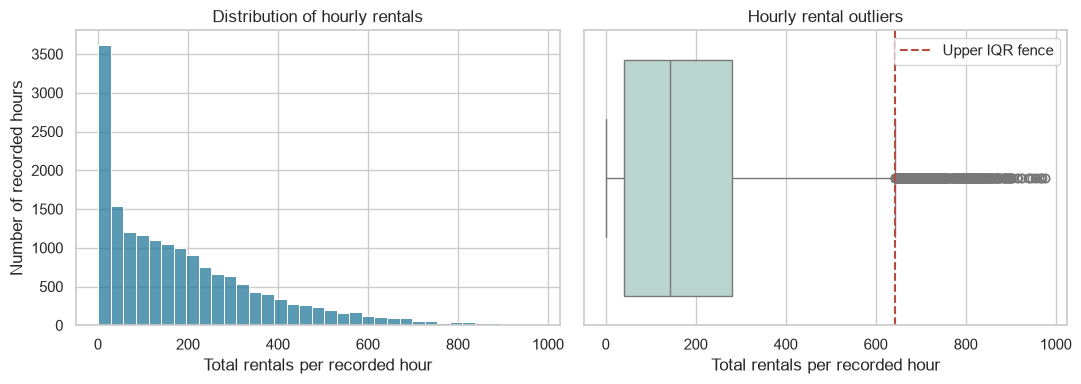

Mean rentals: 189.5; median: 142
Skewness: 1.28; maximum: 977


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=clean, x='total_rentals', bins=35, ax=axes[0], color='#24789A')
axes[0].set(title='Distribution of hourly rentals', xlabel='Total rentals per recorded hour',
            ylabel='Number of recorded hours')
sns.boxplot(data=clean, x='total_rentals', ax=axes[1], color='#B6D9D0')
axes[1].axvline(upper_rental_fence, color='#B34C3E', linestyle='--', label='Upper IQR fence')
axes[1].set(title='Hourly rental outliers', xlabel='Total rentals per recorded hour', ylabel='')
axes[1].legend()
plt.tight_layout()
plt.show()
print(f'Mean rentals: {clean.total_rentals.mean():.1f}; median: {clean.total_rentals.median():.0f}')
print(f'Skewness: {clean.total_rentals.skew():.2f}; maximum: {clean.total_rentals.max()}')

**Insight:** Demand is right-skewed: the mean is 189.5 rentals per recorded hour, compared with
a median of 142. The largest count is 977. Later regression models should be checked for
larger errors during busy hours. A transformed target can be compared with the original target
using training data, with predictions converted back to rental counts before evaluation.

### 4.2 Weather distributions
The weather measurements are already normalized. Their different distributions still matter
when choosing a scaler for distance-based methods later.

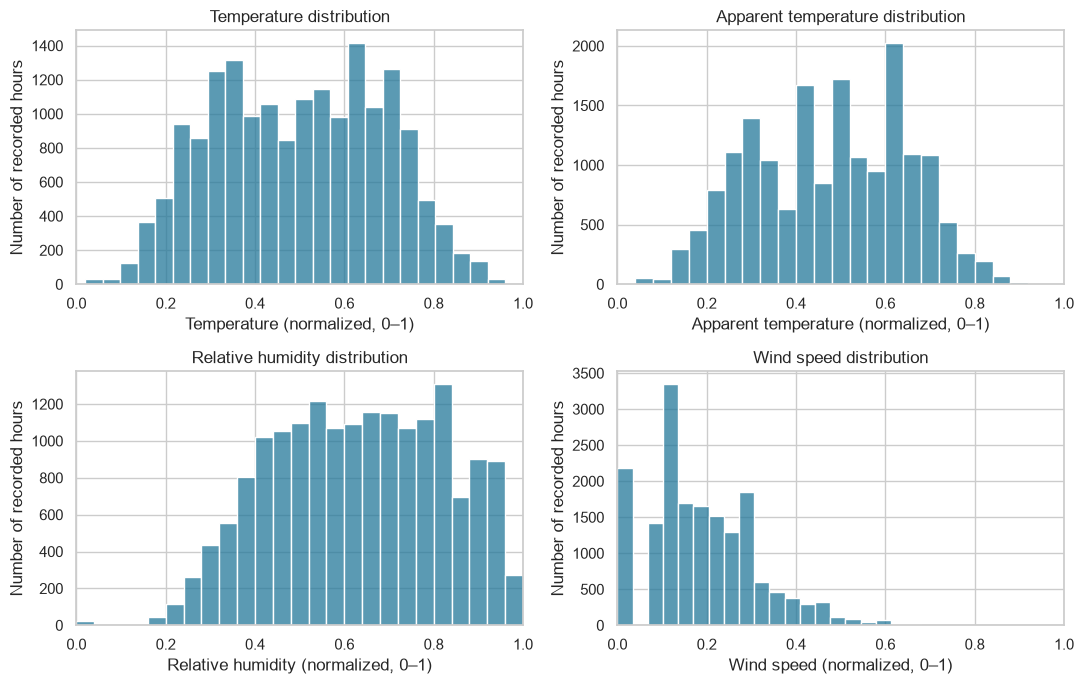

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
weather_titles = {
    'temperature_norm': 'Temperature', 'feels_like_norm': 'Apparent temperature',
    'humidity_norm': 'Relative humidity', 'windspeed_norm': 'Wind speed'
}
for ax, (col, title) in zip(axes.flat, weather_titles.items()):
    sns.histplot(data=clean, x=col, bins=25, ax=ax, color='#24789A')
    ax.set(title=f'{title} distribution', xlabel=f'{title} (normalized, 0–1)',
           ylabel='Number of recorded hours', xlim=(0, 1))
plt.tight_layout()
plt.show()

**Insight:** Wind speed is concentrated toward the lower end, while humidity spans much of
its range. The humidity values near zero deserve the review described above. For clustering
and k-NN, fit scaling on the training data where applicable rather than assuming that all
normalized measurements have the same spread.

### 4.3 Hourly demand on working and non-working days

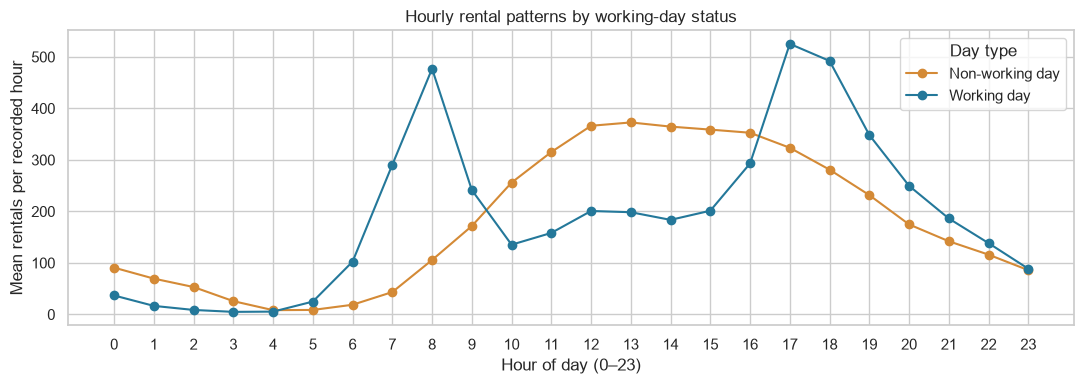

working_day,Non-working day,Working day
hour,,
8,105.654,477.006
13,372.732,198.430
17,323.550,525.291


In [8]:
# Average only the observed records; missing hours are not treated as zero demand.
hourly_profile = clean.groupby(['hour', 'working_day'], observed=True)['total_rentals'].mean().unstack()
fig, ax = plt.subplots(figsize=(11, 4))
for group, label, color in [(0, 'Non-working day', '#D48A36'), (1, 'Working day', '#24789A')]:
    ax.plot(hourly_profile.index.astype(int), hourly_profile[group], marker='o',
            label=label, color=color)
ax.set(title='Hourly rental patterns by working-day status', xlabel='Hour of day (0–23)',
       ylabel='Mean rentals per recorded hour', xticks=range(24))
ax.legend(title='Day type')
plt.tight_layout()
plt.show()
display(hourly_profile.loc[[8, 13, 17]].rename(columns={0: 'Non-working day', 1: 'Working day'}))

**Insight:** Working-day averages peak around 8:00 a.m. (477.0 rentals) and 5:00 p.m.
(525.3 rentals). Non-working days have a broader midday peak, reaching 372.7 at 1:00 p.m.
This is consistent with different commuting and leisure patterns, although trip purposes are
not recorded. Future feature engineering should represent hour cycles and the interaction
between hour and working-day status.

### 4.4 Monthly patterns and year-to-year change

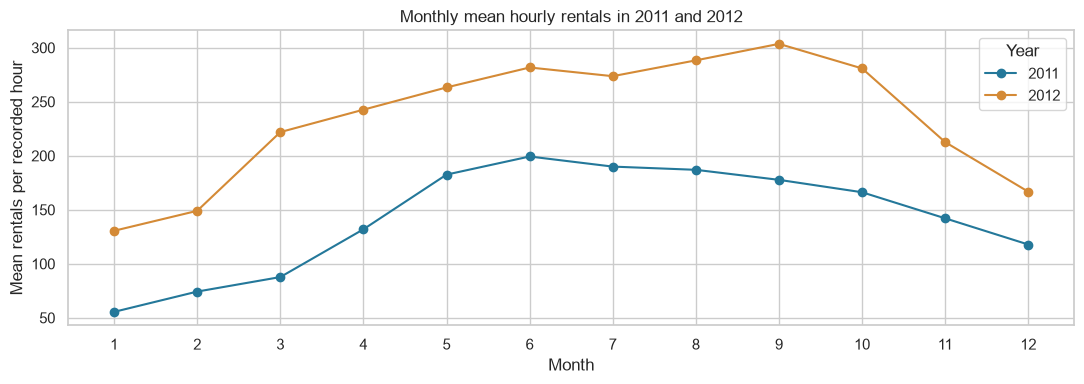

,Mean rentals per recorded hour
year,
2011,143.794
2012,234.666


Change in mean hourly rentals, 2011 to 2012: 63.2%


In [9]:
monthly_profile = clean.groupby(['month', 'year'], observed=True)['total_rentals'].mean().unstack()
fig, ax = plt.subplots(figsize=(11, 4))
for year, color in [(2011, '#24789A'), (2012, '#D48A36')]:
    ax.plot(monthly_profile.index.astype(int), monthly_profile[year], marker='o',
            label=str(year), color=color)
ax.set(title='Monthly mean hourly rentals in 2011 and 2012', xlabel='Month',
       ylabel='Mean rentals per recorded hour', xticks=range(1, 13))
ax.legend(title='Year')
plt.tight_layout()
plt.show()
yearly_mean = clean.groupby('year', observed=True)['total_rentals'].mean()
display(yearly_mean.rename('Mean rentals per recorded hour').to_frame())
print(f'Change in mean hourly rentals, 2011 to 2012: {(yearly_mean.loc[2012] / yearly_mean.loc[2011] - 1) * 100:.1f}%')

**Insight:** Average hourly demand is lower in winter months and higher in warmer months.
The observed hourly mean increases from 143.8 in 2011 to 234.7 in 2012, a 63.2% increase.
This is a descriptive difference, not proof of its cause. Use chronological training and test
periods and validation windows defined by dates so later models are evaluated on subsequent
observations. Two years of data do not establish that these patterns will continue today.

### 4.5 Weather categories and demand

,recorded_hours,mean_rentals,median_rentals
weather,,,
Clear / partly cloudy,11413,204.869,159.000
Mist / cloudy,4544,175.165,133.000
Light rain / snow,1419,111.579,63.000
Heavy precipitation,3,74.333,36.000


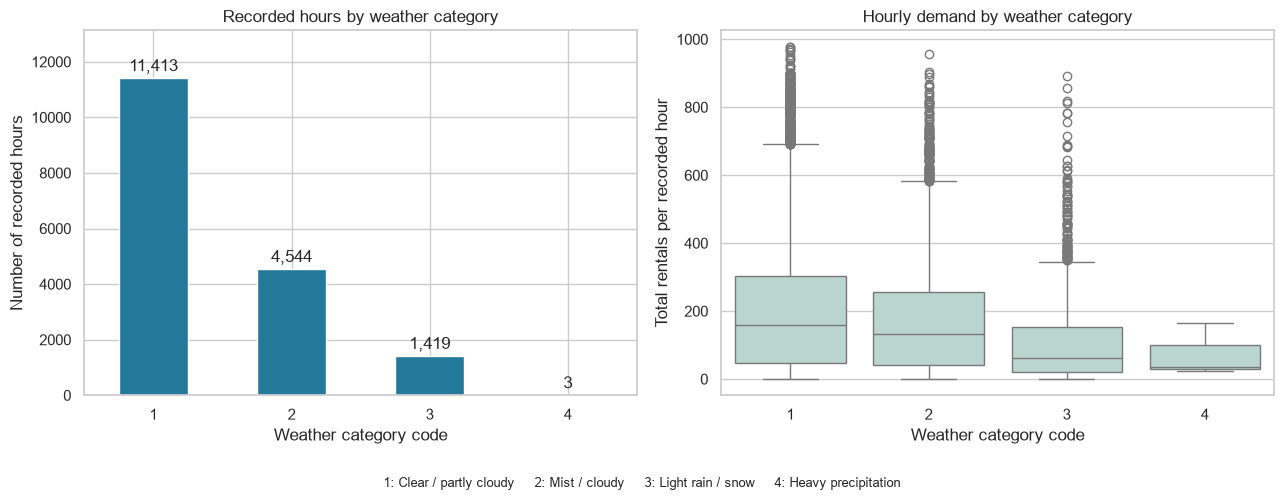

In [10]:
weather_labels = {1: 'Clear / partly cloudy', 2: 'Mist / cloudy',
                  3: 'Light rain / snow', 4: 'Heavy precipitation'}
weather_summary = clean.groupby('weather', observed=True)['total_rentals'].agg(
    recorded_hours='size', mean_rentals='mean', median_rentals='median')
display(weather_summary.rename(index=weather_labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
weather_summary['recorded_hours'].plot.bar(ax=axes[0], color='#24789A', rot=0)
axes[0].set(title='Recorded hours by weather category', xlabel='Weather category code',
            ylabel='Number of recorded hours')
for i, count in enumerate(weather_summary['recorded_hours']):
    axes[0].annotate(f'{count:,}', (i, count), xytext=(0, 5),
                     textcoords='offset points', ha='center')
axes[0].set_ylim(0, weather_summary['recorded_hours'].max() * 1.15)
sns.boxplot(data=clean, x='weather', y='total_rentals', ax=axes[1], color='#B6D9D0')
axes[1].set(title='Hourly demand by weather category', xlabel='Weather category code',
            ylabel='Total rentals per recorded hour')
fig.text(0.5, 0.01, '1: Clear / partly cloudy     2: Mist / cloudy     3: Light rain / snow     4: Heavy precipitation',
         ha='center', fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

**Insight:** Clear-weather hours average 204.9 rentals, compared with 111.6 in light rain or snow.
Other factors such as hour and season may explain part of this difference. Heavy precipitation
has only **3 observations**, so its average of 74.3 is too uncertain for a broad conclusion.
Future encoding should handle rare or previously unseen categories. Association rules should
require adequate support and exclude combinations that merely restate calendar definitions.

### 4.6 Feature relationships
The correlation chart includes continuous measurements and the outcome. It excludes the row
identifier and nominal category codes. Casual and registered rentals are also excluded because
their sum defines the outcome.

,temperature_norm,feels_like_norm,humidity_norm,windspeed_norm,total_rentals
temperature_norm,1.000,0.988,-0.070,-0.023,0.405
feels_like_norm,0.988,1.000,-0.052,-0.062,0.401
humidity_norm,-0.070,-0.052,1.000,-0.290,-0.323
windspeed_norm,-0.023,-0.062,-0.290,1.000,0.093
total_rentals,0.405,0.401,-0.323,0.093,1.000


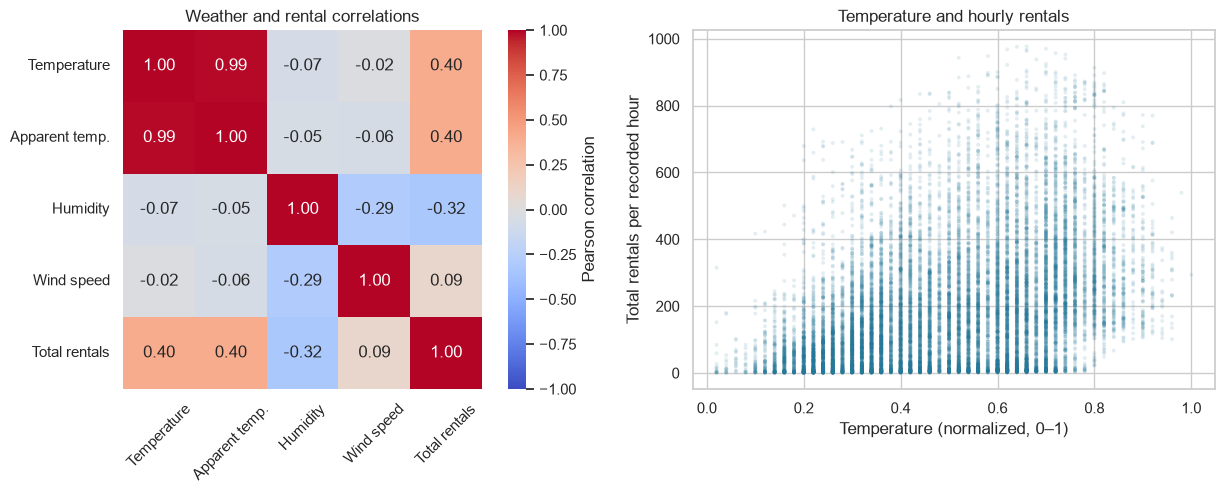

In [11]:
relation_columns = ['temperature_norm', 'feels_like_norm', 'humidity_norm',
                    'windspeed_norm', 'total_rentals']
correlations = clean[relation_columns].corr()
display(correlations)
labels = ['Temperature', 'Apparent temp.', 'Humidity', 'Wind speed', 'Total rentals']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            square=True, xticklabels=labels, yticklabels=labels, ax=axes[0],
            cbar_kws={'label': 'Pearson correlation'})
axes[0].set_title('Weather and rental correlations')
axes[0].tick_params(axis='x', rotation=45)
axes[0].tick_params(axis='y', rotation=0)
axes[1].scatter(clean['temperature_norm'], clean['total_rentals'], s=8,
                alpha=0.12, color='#24789A', edgecolors='none')
axes[1].set(title='Temperature and hourly rentals', xlabel='Temperature (normalized, 0–1)',
            ylabel='Total rentals per recorded hour')
plt.tight_layout()
plt.show()

**Insight:** Temperature has a moderate positive correlation with rentals (`r = 0.405`),
while humidity has a negative correlation (`r = −0.323`). The scatterplot shows wide variation
at the same temperature, so temperature alone is insufficient to predict demand.
Temperature and apparent temperature are strongly correlated (`r = 0.988`). Compare keeping
one of them with Ridge regularization later. These associations do not establish causation.

## 5. Main findings and next modeling steps

| EDA finding | Decision for the next deliverables |
|---|---|
| Hourly demand is right-skewed, with valid busy-hour extremes. | Retain extremes and examine prediction errors by demand level. Compare a target transformation using training data. |
| Working and non-working days have different hourly profiles. | Create cyclic hour features and working-day interactions in Deliverable 2. |
| Seasonal patterns and higher demand in 2012 are visible. | Use chronological evaluation and date-based validation windows. Full-data EDA here is descriptive; future test results will not be an entirely unseen confirmation. |
| Temperature and apparent temperature are nearly redundant. | Compare feature selection with regularized regression. |
| Heavy precipitation is rare and humidity has a questionable day. | Handle rare categories safely and compare model sensitivity to humidity readings. |
| Casual plus registered rentals equals the total. | Exclude both components from rental prediction; exclude all three count columns when predicting a demand class. |

For **Deliverable 2**, compare Multiple Linear Regression and Ridge Regression, with feature
engineering and R², MSE, RMSE, and cross-validation. Fit imputation, scaling, and encoding only
inside training folds if needed. Because some hours are absent, use calendar-based expanding
validation windows rather than assuming equal-duration row blocks. If weather is used for advance
forecasts, forecasts available at prediction time are needed; recorded weather here describes
conditions during the hour.

For **Deliverable 3**, compare a Decision Tree and k-NN classifier, tune one with grid search,
and report confusion matrices, ROC curves, accuracy, and F1. Define a high-demand threshold from
training counts and freeze it for validation and testing. Use K-Means on standardized weather
and encoded time features, then profile groups using rentals. For Apriori or FP-Growth, encode
hour-level conditions and demand groups as items. Report support, confidence, and lift; exclude
deterministic rules such as weekend status implying non-working-day status.

**Limitations:** These are historical, system-wide records from one city. They do not describe
individual riders, station availability, unmet demand, or neighborhoods. The findings can inform
planning questions, but cannot justify individual decisions or current demand estimates without
new data. Only Deliverable 1 is implemented here.

## 6. Save the cleaned dataset and verify the result
The export preserves every observed hour and every weather and rental measurement. It changes
names and types, converts the year code, removes the identifier, and adds a timestamp.
No model has been trained or statistical scaling fitted in this deliverable.

In [12]:
# These checks make discrepancies visible before the file is used in later work.
assert len(clean) >= 500 and clean.shape[1] >= 10
assert len(clean) == len(raw) - exact_duplicates
assert not clean.isna().any().any()
assert not clean['timestamp'].duplicated().any()
assert clean['timestamp'].is_monotonic_increasing
assert (clean['total_rentals'] == clean['casual_rentals'] + clean['registered_rentals']).all()
assert 'instant' not in clean.columns

OUTPUT_PATH = ROOT / 'bike_sharing_cleaned.csv'
clean.to_csv(OUTPUT_PATH, index=False, date_format='%Y-%m-%d %H:%M:%S')
saved = pd.read_csv(OUTPUT_PATH, parse_dates=['date', 'timestamp'])
assert saved.shape == clean.shape
np.testing.assert_array_equal(saved['total_rentals'].to_numpy(), clean['total_rentals'].to_numpy())
print(f'Saved {OUTPUT_PATH.name}: {len(saved):,} rows and {saved.shape[1]} columns')
print('Validation passed: complete cells, unique sorted hours, valid counts, and consistent export.')
print('When loading the CSV later, parse date and timestamp and restore category types before modeling.')

Saved bike_sharing_cleaned.csv: 17,379 rows and 17 columns
Validation passed: complete cells, unique sorted hours, valid counts, and consistent export.
When loading the CSV later, parse date and timestamp and restore category types before modeling.


## References
Fanaee-T, H. (2013). *Bike sharing* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894

Fanaee-T, H., & Gama, J. (2014). Event labeling combining ensemble detectors and background knowledge.
*Progress in Artificial Intelligence, 2*, 113–127. https://doi.org/10.1007/s13748-013-0040-3

Wu, D. (2024). *Data mining with Python: Theory, application, and case studies*. CRC Press.